# Credit Risk and Credit Card Default Prediction

## Project objective

Build and evaluate models that estimate the probability of a customer defaulting on the next month's credit-card payment, using historical demographic, credit-limit, repayment-status, bill-statement and payment information.

- Official dataset page: https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients


In [ ]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, classification_report,
    log_loss, brier_score_loss, precision_recall_curve, roc_curve,
    ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("Setup complete.")

Setup complete.


In [ ]:
import os
import glob
import pandas as pd

possible_files = [
    "/content/default of credit card clients.xls",
    "/content/default of credit card clients.xlsx"
]
DATA_PATH = next((path for path in possible_files if os.path.exists(path)), None)

if DATA_PATH is None:
    available_excel_files = glob.glob("/content/*.xls") + glob.glob("/content/*.xlsx")
    raise FileNotFoundError(
        "Dataset not found in /content. Upload 'default of credit card clients.xls' "
        "or 'default of credit card clients.xlsx' using the Colab Files panel. "
        f"Excel files currently found: {available_excel_files}"
    )

# xlrd is required only for the legacy .xls format.
if DATA_PATH.lower().endswith(".xls"):
    try:
        import xlrd
    except ImportError:
        %pip install -q xlrd
        import xlrd

df = pd.read_excel(DATA_PATH, header=1)

print("Dataset loaded successfully!")
print("File:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
File: /content/default of credit card clients.xlsx
Shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 5. Data validation and data dictionary

The expected dataset has 30,000 observations and 25 columns. Validate the file before analysis; do not silently assume every download is identical.

In [ ]:
expected_target = "default payment next month"
assert expected_target in df.columns, f"Target column '{expected_target}' not found."
assert df.shape[1] == 25, f"Expected 25 columns; found {df.shape[1]}."

print("Shape:", df.shape)
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\nExact duplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
display(df[expected_target].value_counts(dropna=False).rename("count").to_frame())

Shape: (30000, 25)

Data types:


,dtype
ID,int64
LIMIT_BAL,int64
SEX,int64
EDUCATION,int64
MARRIAGE,int64
AGE,int64
PAY_0,int64
PAY_2,int64
PAY_3,int64
PAY_4,int64



Missing values:


,missing_count
ID,0
LIMIT_BAL,0
SEX,0
EDUCATION,0
MARRIAGE,0
AGE,0
PAY_0,0
PAY_2,0
PAY_3,0
PAY_4,0



Exact duplicate rows: 0

Target distribution:


,count
default payment next month,
0,23364
1,6636


### Feature reference

| Column(s) | Meaning |
|---|---|
| `ID` | Row/customer identifier; excluded from modelling |
| `LIMIT_BAL` | Credit limit (NT dollars) |
| `SEX`, `EDUCATION`, `MARRIAGE`, `AGE` | Demographic / account attributes |
| `PAY_0`, `PAY_2`–`PAY_6` | Repayment status over recent months; positive values indicate months of delay, 0 indicates on-time, negative codes represent paid/no consumption or other non-delay states in the original coding |
| `BILL_AMT1`–`BILL_AMT6` | Monthly bill statement amounts |
| `PAY_AMT1`–`PAY_AMT6` | Monthly previous payment amounts |
| `default payment next month` | Target: 1 = default, 0 = no default |

**Important coding note:** `PAY_0` is the original column name for the most recent repayment status; it is not renamed to avoid losing traceability to the source.

In [ ]:
print("Numeric summary:")
display(df.describe().T)

print("\nTarget values:", sorted(df[expected_target].dropna().unique().tolist()))
print("Target class proportions:")
display(df[expected_target].value_counts(normalize=True).rename("proportion").to_frame())

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
ID,"30,000.000","15,000.500","8,660.398",1.000,"7,500.750","15,000.500","22,500.250","30,000.000"
LIMIT_BAL,"30,000.000","167,484.323","129,747.662","10,000.000","50,000.000","140,000.000","240,000.000","1,000,000.000"
SEX,"30,000.000",1.604,0.489,1.000,1.000,2.000,2.000,2.000
EDUCATION,"30,000.000",1.853,0.790,0.000,1.000,2.000,2.000,6.000
MARRIAGE,"30,000.000",1.552,0.522,0.000,1.000,2.000,2.000,3.000
AGE,"30,000.000",35.486,9.218,21.000,28.000,34.000,41.000,79.000
PAY_0,"30,000.000",-0.017,1.124,-2.000,-1.000,0.000,0.000,8.000
PAY_2,"30,000.000",-0.134,1.197,-2.000,-1.000,0.000,0.000,8.000
PAY_3,"30,000.000",-0.166,1.197,-2.000,-1.000,0.000,0.000,8.000
PAY_4,"30,000.000",-0.221,1.169,-2.000,-1.000,0.000,0.000,8.000



Target values: [0, 1]
Target class proportions:


,proportion
default payment next month,
0,0.779
1,0.221


## 6. Data quality checks and cleaning decisions

We check invalid codes in categorical fields and the repayment-status variables. The UCI data includes special/unknown codes (for example education 0, 5, 6 and marriage 0). Rather than deleting those observations, we group them as `Unknown/Other`. This is a transparent treatment of source coding, not an assertion that the values are valid real-world categories.

We retain the original target and remove only exact duplicate records if any exist. The source file inspected for this project has no missing values or exact duplicate rows.

In [ ]:
df = df.copy()
df = df.drop_duplicates().reset_index(drop=True)

# Validate target is binary and remove rows with missing target if any.
df = df[df[expected_target].isin([0, 1])].copy()

# Standardise known special category codes without altering the original raw dataframe.
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

print("Rows after quality checks:", len(df))
print("Education codes after grouping:", sorted(df["EDUCATION"].unique()))
print("Marriage codes after grouping:", sorted(df["MARRIAGE"].unique()))

Rows after quality checks: 30000
Education codes after grouping: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Marriage codes after grouping: [np.int64(1), np.int64(2), np.int64(3)]


## 7. Exploratory data analysis (EDA)

### 7.1 Target balance

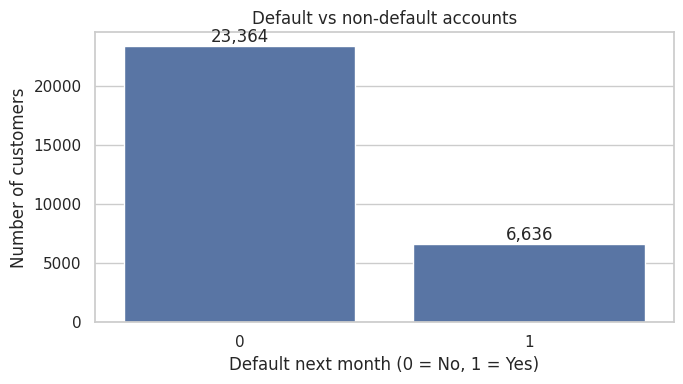

Observed default rate: 22.12%


In [ ]:
target_counts = df[expected_target].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=target_counts.index.astype(str), y=target_counts.values, ax=ax)
ax.set(title="Default vs non-default accounts", xlabel="Default next month (0 = No, 1 = Yes)", ylabel="Number of customers")
for i, v in enumerate(target_counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

default_rate = df[expected_target].mean()
print(f"Observed default rate: {default_rate:.2%}")

### 7.2 Univariate distributions

Inspect credit limit, age, repayment status, bill amounts and payment amounts. Long-tailed financial variables may be better understood using percentiles and boxplots than relying on means alone.

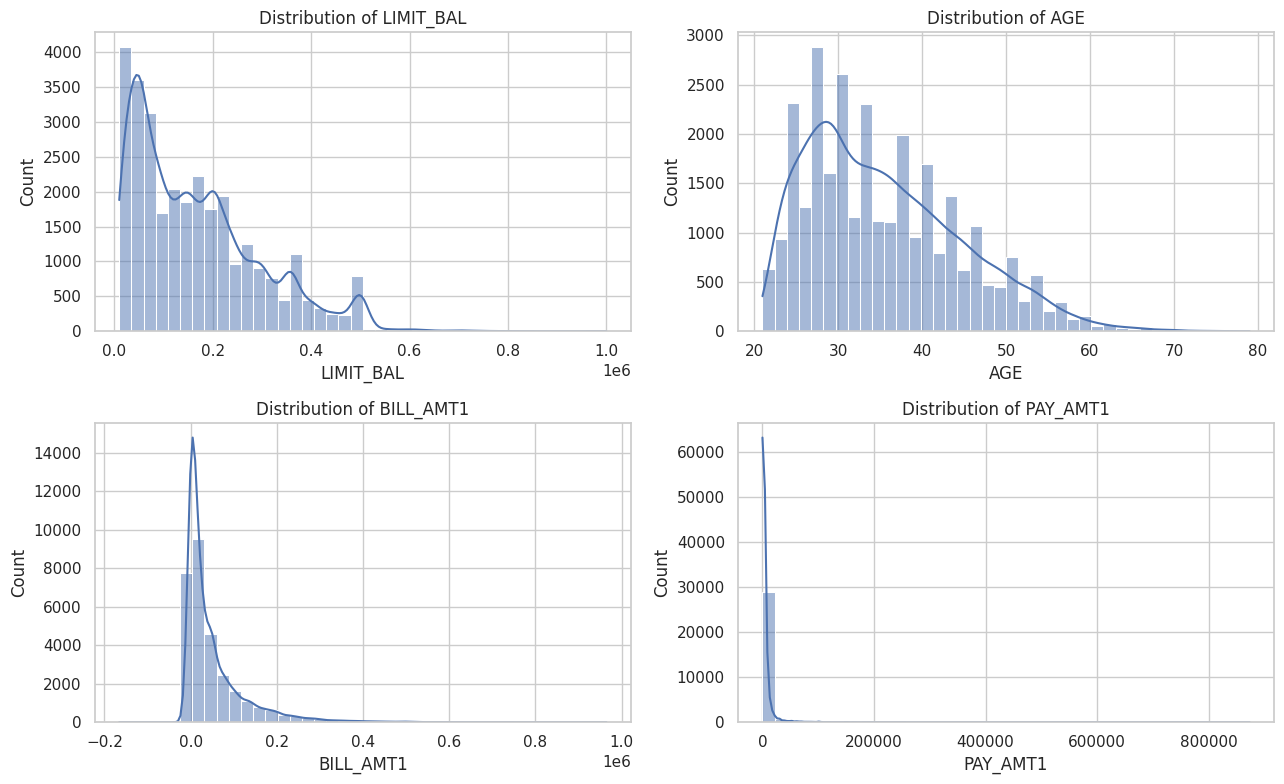

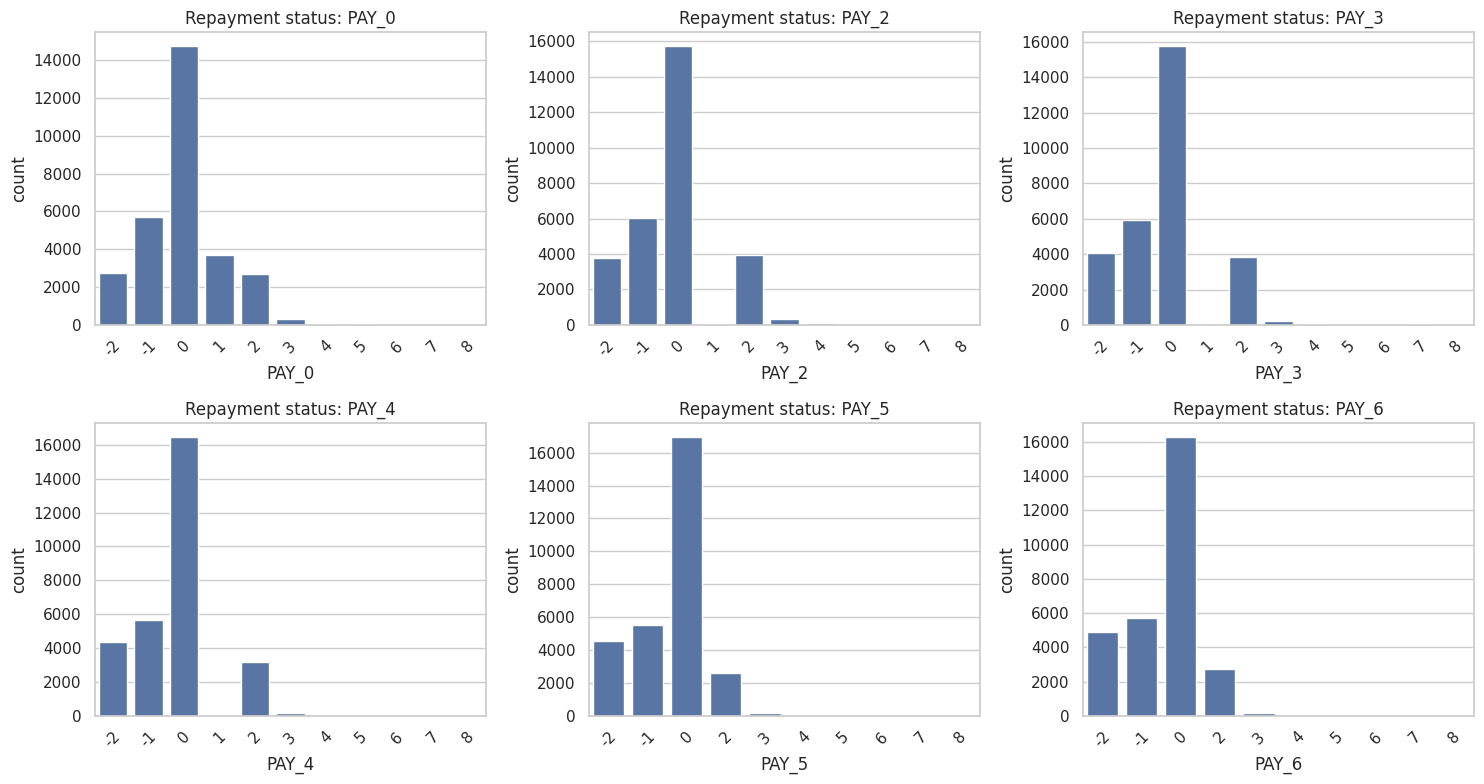

In [ ]:
numeric_to_plot = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for col, ax in zip(numeric_to_plot, axes.flat):
    sns.histplot(df[col], bins=40, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col, ax in zip(["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"], axes.flat):
    order = sorted(df[col].unique())
    sns.countplot(data=df, x=col, order=order, ax=ax)
    ax.set_title(f"Repayment status: {col}")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### 7.3 Default rate by key variables

Compare observed default rates across credit-limit bands, age bands, repayment statuses and account categories. These are descriptive associations, not causal effects.

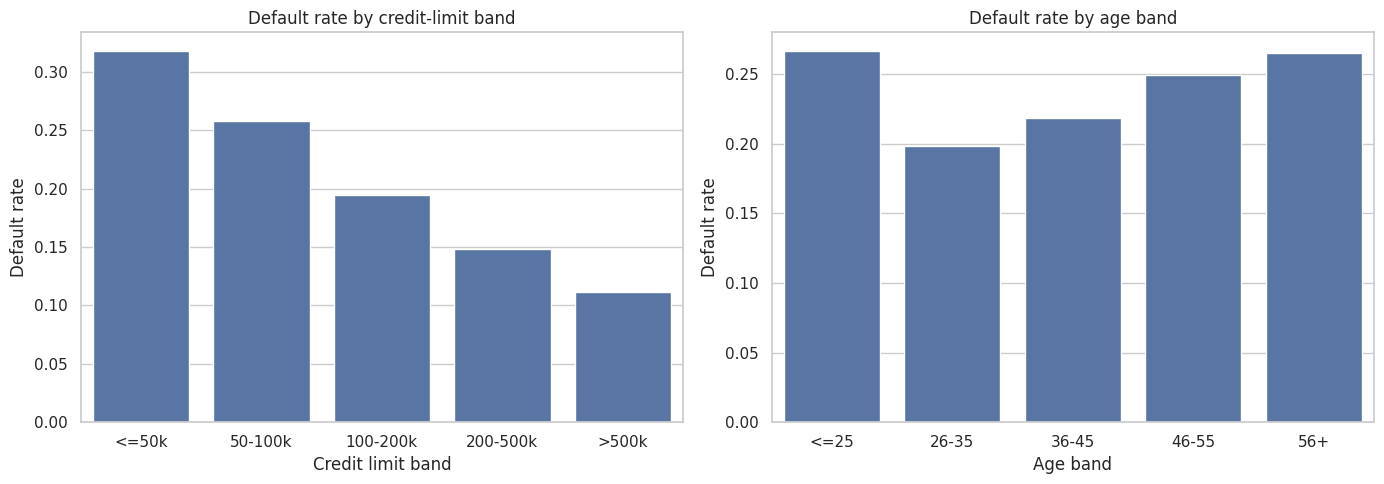

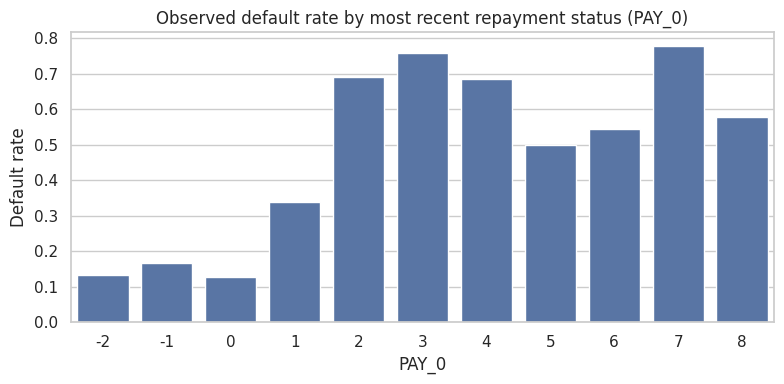

In [ ]:
eda_df = df.copy()
eda_df["LIMIT_BAL_BAND"] = pd.cut(
    eda_df["LIMIT_BAL"],
    bins=[-1, 50000, 100000, 200000, 500000, np.inf],
    labels=["<=50k", "50-100k", "100-200k", "200-500k", ">500k"]
)
eda_df["AGE_BAND"] = pd.cut(
    eda_df["AGE"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["<=25", "26-35", "36-45", "46-55", "56+"]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=eda_df, x="LIMIT_BAL_BAND", y=expected_target, errorbar=None, ax=axes[0])
axes[0].set(title="Default rate by credit-limit band", xlabel="Credit limit band", ylabel="Default rate")
sns.barplot(data=eda_df, x="AGE_BAND", y=expected_target, errorbar=None, ax=axes[1])
axes[1].set(title="Default rate by age band", xlabel="Age band", ylabel="Default rate")
plt.tight_layout()
plt.show()

pay_rate = eda_df.groupby("PAY_0", observed=False)[expected_target].mean().reset_index()
plt.figure(figsize=(8, 4))
sns.barplot(data=pay_rate, x="PAY_0", y=expected_target)
plt.title("Observed default rate by most recent repayment status (PAY_0)")
plt.xlabel("PAY_0")
plt.ylabel("Default rate")
plt.tight_layout()
plt.show()

### 7.4 Correlation and multivariate patterns

Correlation is useful for an initial scan but does not establish causality. Strong correlations between consecutive bill amounts are expected because they represent adjacent months.

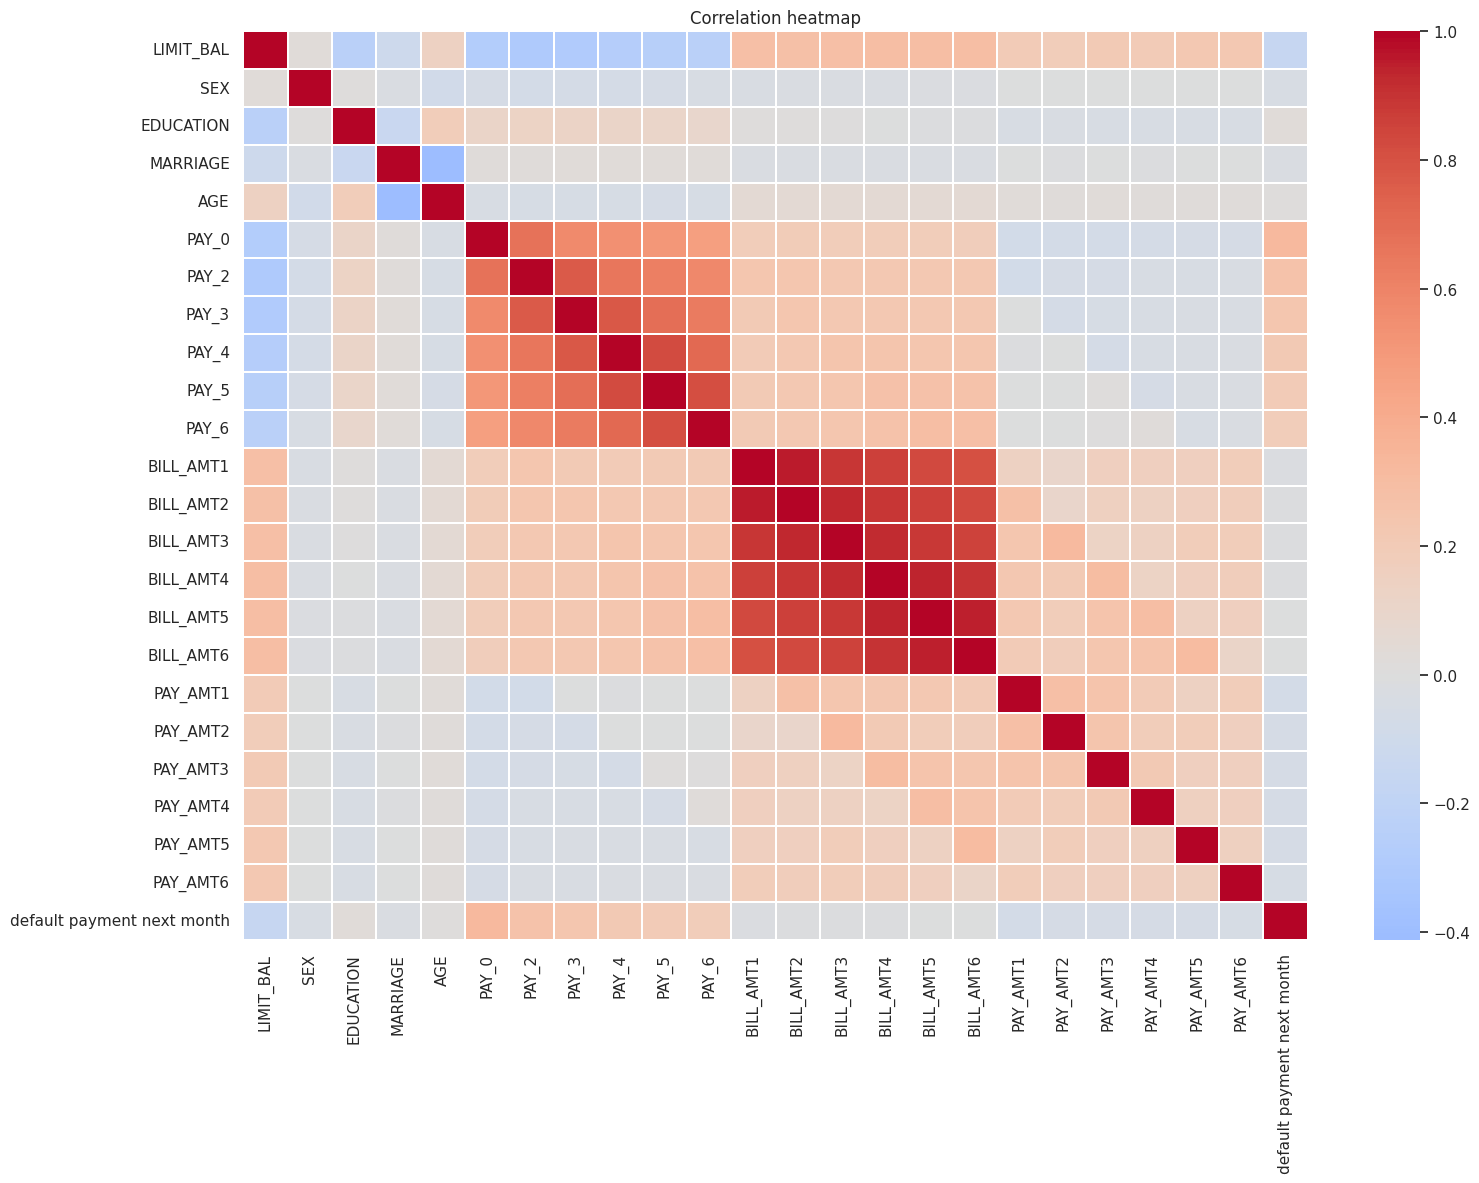

,correlation_with_default
PAY_0,0.325
PAY_2,0.264
PAY_3,0.235
PAY_4,0.217
PAY_5,0.204
PAY_6,0.187
LIMIT_BAL,-0.154
PAY_AMT1,-0.073
PAY_AMT2,-0.059
PAY_AMT4,-0.057


In [ ]:
corr = df.drop(columns=["ID"], errors="ignore").corr(numeric_only=True)
plt.figure(figsize=(16, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.2)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

corr_target = corr[expected_target].drop(expected_target).sort_values(key=lambda s: s.abs(), ascending=False)
display(corr_target.to_frame("correlation_with_default"))

## 8. Feature engineering

We create compact summaries of the six months of bill, payment and repayment-status history. These features are derived from historical columns only.

- `TOTAL_BILL_6M`, `TOTAL_PAYMENT_6M`: six-month totals
- `AVG_BILL_6M`, `AVG_PAYMENT_6M`: six-month averages
- `PAYMENT_TO_BILL_RATIO`: recent payment relative to recent bill, protected against division by zero
- `DELAY_COUNT_6M`: number of months with a positive delay code
- `MAX_DELAY_STATUS`, `AVG_REPAYMENT_STATUS`: repayment history summaries
- `CREDIT_UTILIZATION`: latest bill amount relative to credit limit

The ratio and utilization are descriptive engineered variables; extreme values are possible and will be handled through robust model evaluation rather than arbitrary deletion.

In [ ]:
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
payment_cols = [f"PAY_AMT{i}" for i in range(1, 7)]
pay_status_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

df["TOTAL_BILL_6M"] = df[bill_cols].sum(axis=1)
df["TOTAL_PAYMENT_6M"] = df[payment_cols].sum(axis=1)
df["AVG_BILL_6M"] = df[bill_cols].mean(axis=1)
df["AVG_PAYMENT_6M"] = df[payment_cols].mean(axis=1)
df["PAYMENT_TO_BILL_RATIO"] = df["TOTAL_PAYMENT_6M"] / df["TOTAL_BILL_6M"].replace(0, np.nan)
df["PAYMENT_TO_BILL_RATIO"] = df["PAYMENT_TO_BILL_RATIO"].replace([np.inf, -np.inf], np.nan)
df["DELAY_COUNT_6M"] = (df[pay_status_cols] > 0).sum(axis=1)
df["MAX_DELAY_STATUS"] = df[pay_status_cols].max(axis=1)
df["AVG_REPAYMENT_STATUS"] = df[pay_status_cols].mean(axis=1)
df["CREDIT_UTILIZATION"] = df["BILL_AMT1"] / df["LIMIT_BAL"].replace(0, np.nan)
df["CREDIT_UTILIZATION"] = df["CREDIT_UTILIZATION"].replace([np.inf, -np.inf], np.nan)

engineered_cols = [
    "TOTAL_BILL_6M", "TOTAL_PAYMENT_6M", "AVG_BILL_6M", "AVG_PAYMENT_6M",
    "PAYMENT_TO_BILL_RATIO", "DELAY_COUNT_6M", "MAX_DELAY_STATUS",
    "AVG_REPAYMENT_STATUS", "CREDIT_UTILIZATION"
]
display(df[engineered_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
TOTAL_BILL_6M,"30,000.000","269,861.671","379,564.331","-336,259.000","28,688.000","126,311.000","342,626.500","5,263,883.000"
TOTAL_PAYMENT_6M,"30,000.000","31,651.393","60,827.678",0.000,"6,679.750","14,383.000","33,503.500","3,764,066.000"
AVG_BILL_6M,"30,000.000","44,976.945","63,260.722","-56,043.167","4,781.333","21,051.833","57,104.417","877,313.833"
AVG_PAYMENT_6M,"30,000.000","5,275.232","10,137.946",0.000,"1,113.292","2,397.167","5,583.917","627,344.333"
PAYMENT_TO_BILL_RATIO,"29,130.000",0.392,7.784,-546.929,0.042,0.092,0.615,797.000
DELAY_COUNT_6M,"30,000.000",0.834,1.554,0.000,0.000,0.000,1.000,6.000
MAX_DELAY_STATUS,"30,000.000",0.439,1.345,-2.000,0.000,0.000,2.000,8.000
AVG_REPAYMENT_STATUS,"30,000.000",-0.182,0.982,-2.000,-0.833,0.000,0.000,6.000
CREDIT_UTILIZATION,"30,000.000",0.424,0.411,-0.620,0.022,0.314,0.830,6.455


## 9. Define features and target

`ID` is excluded. We retain the original component columns alongside engineered features so models can learn from both detailed history and summaries. Demographic attributes are included because they are part of the academic benchmark, but their use raises fairness and legal concerns in real lending. A real deployment would require jurisdiction-specific legal review, fairness testing, governance and a defensible feature policy.

In [ ]:
TARGET = expected_target
X = df.drop(columns=[TARGET, "ID"], errors="ignore")
y = df[TARGET].astype(int)

categorical_features = ["SEX", "EDUCATION", "MARRIAGE"]
numeric_features = [c for c in X.columns if c not in categorical_features]

print("Feature count:", X.shape[1])
print("Categorical features:", categorical_features)
print("Numeric feature count:", len(numeric_features))

Feature count: 32
Categorical features: ['SEX', 'EDUCATION', 'MARRIAGE']
Numeric feature count: 29


## 10. Train, validation and test split

We create three partitions:
- **Training-fit set:** used for cross-validation model comparison and hyperparameter tuning.
- **Validation set:** used only to choose the operating probability threshold.
- **Final test set:** held aside until the final model is selected and thresholded.

The random seed is changed from the earlier run so this notebook uses a fresh holdout split. All splits are stratified to preserve the default rate.

In [ ]:
# First create a fresh, untouched test set.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=2026, stratify=y
)

# Split the remaining training data into model-fit and threshold-validation partitions.
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train, y_train, test_size=0.20, random_state=RANDOM_STATE, stratify=y_train
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Model-fit shape:", X_fit.shape)
print("Threshold-validation shape:", X_valid.shape)
print("Final test shape:", X_test.shape)
print("Default rates:", {
    "fit": round(y_fit.mean(), 4),
    "validation": round(y_valid.mean(), 4),
    "test": round(y_test.mean(), 4)
})

Model-fit shape: (19200, 32)
Threshold-validation shape: (4800, 32)
Final test shape: (6000, 32)
Default rates: {'fit': np.float64(0.2212), 'validation': np.float64(0.2212), 'test': np.float64(0.2212)}


## 11. Baseline model: majority-class benchmark

A baseline is useful to understand why accuracy alone can be misleading. The majority-class model predicts no default for every account.

In [ ]:
baseline_pred = np.zeros(len(y_test), dtype=int)
print(classification_report(y_test, baseline_pred, zero_division=0))
print("Baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print("Baseline default recall:", round(recall_score(y_test, baseline_pred, zero_division=0), 4))

              precision    recall  f1-score   support

           0       0.78      1.00      0.88      4673
           1       0.00      0.00      0.00      1327

    accuracy                           0.78      6000
   macro avg       0.39      0.50      0.44      6000
weighted avg       0.61      0.78      0.68      6000

Baseline accuracy: 0.7788
Baseline default recall: 0.0


## 12. Train multiple classification models

We compare multiple algorithms using **stratified cross-validation on the model-fit partition only**. The final test set is not used to rank models or select hyperparameters.

Models include Logistic Regression, Decision Tree, Random Forest, Extra Trees, Gradient Boosting, calibrated Linear SVM, XGBoost and LightGBM (the last two are optional if installed).

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=30, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=150, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesClassifier(n_estimators=150, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "Linear SVM (calibrated)": CalibratedClassifierCV(
        estimator=LinearSVC(class_weight="balanced", random_state=RANDOM_STATE), cv=3
    )
}

# Optional gradient-boosting libraries; skipped cleanly if not installed.
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(
        n_estimators=150, max_depth=3, learning_rate=0.05,
        subsample=0.85, colsample_bytree=0.85,
        eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1
    )
    print("XGBoost available.")
except Exception as e:
    print("XGBoost not available; skipped.", type(e).__name__)

try:
    from lightgbm import LGBMClassifier
    models["LightGBM"] = LGBMClassifier(
        n_estimators=150, learning_rate=0.05, num_leaves=20,
        class_weight="balanced", random_state=RANDOM_STATE, verbosity=-1
    )
    print("LightGBM available.")
except Exception as e:
    print("LightGBM not available; skipped.", type(e).__name__)

pipelines = {
    name: Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    for name, estimator in models.items()
}

XGBoost available.
LightGBM available.


In [ ]:
from sklearn.model_selection import cross_validate

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

for name, pipe in pipelines.items():
    print(f"Cross-validating {name} ...")
    scores = cross_validate(
        pipe,
        X_fit,
        y_fit,
        cv=cv,
        scoring={
            "pr_auc": "average_precision",
            "roc_auc": "roc_auc"
        },
        n_jobs=1,
        return_train_score=False
    )
    cv_rows.append({
        "Model": name,
        "CV_PR_AUC_Mean": scores["test_pr_auc"].mean(),
        "CV_PR_AUC_Std": scores["test_pr_auc"].std(),
        "CV_ROC_AUC_Mean": scores["test_roc_auc"].mean(),
        "CV_ROC_AUC_Std": scores["test_roc_auc"].std()
    })

model_cv_results = (
    pd.DataFrame(cv_rows)
    .sort_values("CV_PR_AUC_Mean", ascending=False)
    .reset_index(drop=True)
)

display(model_cv_results.style.format({
    c: "{:.4f}" for c in model_cv_results.select_dtypes(include="number").columns
}))

best_cv_model_name = model_cv_results.loc[0, "Model"]
print(f"Best candidate by mean cross-validated PR-AUC: {best_cv_model_name}")

Cross-validating Logistic Regression ...
Cross-validating Decision Tree ...
Cross-validating Random Forest ...
Cross-validating Extra Trees ...
Cross-validating Gradient Boosting ...
Cross-validating Linear SVM (calibrated) ...
Cross-validating XGBoost ...
Cross-validating LightGBM ...


,Model,CV_PR_AUC_Mean,CV_PR_AUC_Std,CV_ROC_AUC_Mean,CV_ROC_AUC_Std
0,XGBoost,0.5650,0.0080,0.7873,0.0051
1,LightGBM,0.5599,0.0087,0.7849,0.0053
2,Gradient Boosting,0.5580,0.0077,0.7859,0.0048
3,Random Forest,0.5543,0.0090,0.7816,0.0061
4,Extra Trees,0.5502,0.0056,0.7799,0.0061
5,Decision Tree,0.5247,0.0077,0.7653,0.0028
6,Logistic Regression,0.5052,0.0031,0.7590,0.0050
7,Linear SVM (calibrated),0.5019,0.0044,0.7586,0.0053


Best candidate by mean cross-validated PR-AUC: XGBoost


## 13. Cross-validated model comparison

PR-AUC (average precision) is the primary ranking metric because the default class is the minority class. ROC-AUC is also shown as a complementary ranking metric. The mean and standard deviation across folds help show both average performance and variability.

**Selection rule:** choose the candidate with the highest mean validation PR-AUC on the training-fit partition. Do not select a model using final test-set results.

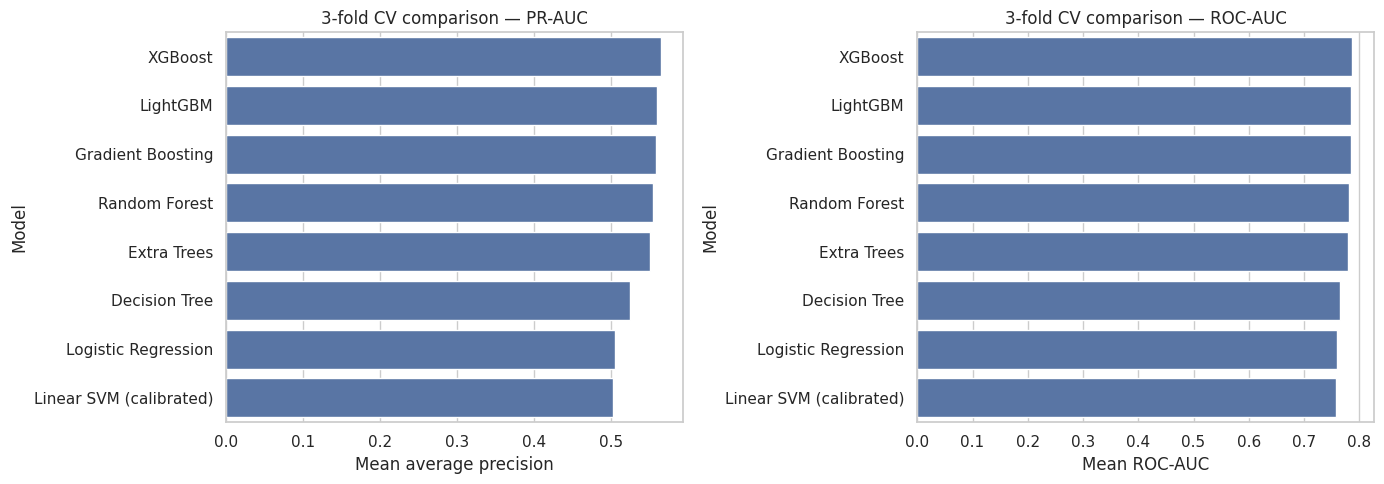

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=model_cv_results, x="CV_PR_AUC_Mean", y="Model", ax=axes[0])
axes[0].set_title("3-fold CV comparison — PR-AUC")
axes[0].set_xlabel("Mean average precision")
sns.barplot(data=model_cv_results, x="CV_ROC_AUC_Mean", y="Model", ax=axes[1])
axes[1].set_title("3-fold CV comparison — ROC-AUC")
axes[1].set_xlabel("Mean ROC-AUC")
plt.tight_layout()
plt.show()

## 14. Imbalanced data handling

The target is imbalanced. We already include class-weighted versions of several models. We also test a Logistic Regression + SMOTE pipeline using cross-validation on the model-fit partition only.

SMOTE is inside an imbalanced-learn pipeline, so synthetic examples are generated separately inside each training fold. The validation and final test partitions are never resampled. This SMOTE experiment is reported separately and is not automatically added to the model-selection candidates.

In [ ]:
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline
    from sklearn.model_selection import cross_validate

    smote_pipe = ImbPipeline(steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ])

    smote_scores = cross_validate(
        smote_pipe,
        X_fit,
        y_fit,
        cv=cv,
        scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"},
        n_jobs=1,
        return_train_score=False
    )

    smote_cv_result = pd.DataFrame([{
        "Model": "Logistic Regression + SMOTE",
        "CV_PR_AUC_Mean": smote_scores["test_pr_auc"].mean(),
        "CV_PR_AUC_Std": smote_scores["test_pr_auc"].std(),
        "CV_ROC_AUC_Mean": smote_scores["test_roc_auc"].mean(),
        "CV_ROC_AUC_Std": smote_scores["test_roc_auc"].std()
    }])

    print("SMOTE cross-validation completed:")
    display(smote_cv_result.style.format({
        c: "{:.4f}" for c in smote_cv_result.select_dtypes(include="number").columns
    }))
except Exception as e:
    print("SMOTE experiment skipped. Install imbalanced-learn to enable it.")
    print("Reason:", repr(e))

SMOTE cross-validation completed:


,Model,CV_PR_AUC_Mean,CV_PR_AUC_Std,CV_ROC_AUC_Mean,CV_ROC_AUC_Std
0,Logistic Regression + SMOTE,0.5083,0.0033,0.7582,0.0048


## 15. Hyperparameter tuning and threshold strategy

After selecting the best algorithm by cross-validation, we tune that algorithm using only the model-fit partition. We then use the separate validation partition to choose a probability threshold. The final test set remains untouched until the final evaluation.

## 16. Hyperparameter tuning of the selected candidate

We tune the algorithm that achieved the highest mean cross-validated PR-AUC. Search spaces are selected for the winning estimator, and RandomizedSearchCV uses stratified 3-fold CV on `X_fit` only.

To keep Colab resource usage manageable, the search uses a small number of candidates and one parallel search worker. The selected model is refitted on `X_fit` by RandomizedSearchCV.

In [ ]:
from sklearn.base import clone

# Model-specific search spaces. Only the winning candidate's space is used.
search_spaces = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1.0, 10.0],
        "model__class_weight": [None, "balanced"]
    },
    "Decision Tree": {
        "model__max_depth": [4, 6, 8, 10, None],
        "model__min_samples_split": [5, 10, 20],
        "model__min_samples_leaf": [5, 10, 20, 30],
        "model__class_weight": [None, "balanced"]
    },
    "Random Forest": {
        "model__n_estimators": [100, 150, 200],
        "model__max_depth": [5, 8, 12, None],
        "model__min_samples_split": [5, 10, 20],
        "model__min_samples_leaf": [2, 5, 10],
        "model__max_features": ["sqrt", 0.5],
        "model__class_weight": ["balanced", "balanced_subsample"]
    },
    "Extra Trees": {
        "model__n_estimators": [100, 150, 200],
        "model__max_depth": [5, 8, 12, None],
        "model__min_samples_split": [5, 10, 20],
        "model__min_samples_leaf": [2, 5, 10],
        "model__max_features": ["sqrt", 0.5],
        "model__class_weight": ["balanced", "balanced_subsample"]
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 150, 200],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [2, 3],
        "model__subsample": [0.8, 1.0],
        "model__min_samples_leaf": [5, 10, 20]
    },
    "Linear SVM (calibrated)": {
        "model__estimator__C": [0.01, 0.1, 1.0, 10.0]
    }
}

if best_cv_model_name == "XGBoost":
    search_spaces["XGBoost"] = {
        "model__n_estimators": [100, 150, 200],
        "model__max_depth": [2, 3, 4],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__subsample": [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0],
        "model__scale_pos_weight": [1, 2, 3]
    }

if best_cv_model_name == "LightGBM":
    search_spaces["LightGBM"] = {
        "model__n_estimators": [100, 150, 200],
        "model__num_leaves": [15, 20, 31],
        "model__max_depth": [-1, 5, 8],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__class_weight": [None, "balanced"]
    }

selected_pipeline = clone(pipelines[best_cv_model_name])
selected_search_space = search_spaces[best_cv_model_name]

random_search = RandomizedSearchCV(
    estimator=selected_pipeline,
    param_distributions=selected_search_space,
    n_iter=6,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    random_state=RANDOM_STATE,
    verbose=2,
    refit=True
)

random_search.fit(X_fit, y_fit)
tuned_model = random_search.best_estimator_

print("Selected algorithm:", best_cv_model_name)
print("Best cross-validated PR-AUC after tuning:", round(random_search.best_score_, 4))
print("Best parameters:")
display(random_search.best_params_)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.1, model__max_depth=3, model__n_estimators=150, model__scale_pos_weight=1, model__subsample=0.8; total time=   0.8s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.1, model__max_depth=3, model__n_estimators=150, model__scale_pos_weight=1, model__subsample=0.8; total time=   0.6s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.1, model__max_depth=3, model__n_estimators=150, model__scale_pos_weight=1, model__subsample=0.8; total time=   0.5s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.1, model__max_depth=2, model__n_estimators=100, model__scale_pos_weight=1, model__subsample=0.8; total time=   0.3s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.1, model__max_depth=2, model__n_estimators=100, model__scale_pos_weight=1, model__subsample=0.8; total time=   0.3s
[CV] END model__colsample_bytree=0.8, model__learning_r

{'model__subsample': 0.8,
 'model__scale_pos_weight': 1,
 'model__n_estimators': 100,
 'model__max_depth': 3,
 'model__learning_rate': 0.1,
 'model__colsample_bytree': 0.8}

## 17. Threshold selection and final untouched test evaluation

First, select a probability threshold on the validation partition by maximising F2. Then refit the tuned model on the full training partition (`X_train`) and evaluate once on the final test partition (`X_test`).

The test set is not used for model selection, hyperparameter tuning or threshold selection.

In [ ]:
# Threshold selection on validation data only.
valid_proba = tuned_model.predict_proba(X_valid)[:, 1]

threshold_rows = []
for threshold in np.arange(0.10, 0.91, 0.05):
    pred_valid = (valid_proba >= threshold).astype(int)
    p = precision_score(y_valid, pred_valid, zero_division=0)
    r = recall_score(y_valid, pred_valid, zero_division=0)
    f1 = f1_score(y_valid, pred_valid, zero_division=0)
    f2 = (5 * p * r / (4 * p + r)) if (4 * p + r) > 0 else 0
    threshold_rows.append({
        "threshold": threshold,
        "precision": p,
        "recall": r,
        "f1": f1,
        "f2": f2
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table)
chosen_threshold = float(
    threshold_table.loc[threshold_table["f2"].idxmax(), "threshold"]
)
print(f"Selected threshold on validation set (max F2): {chosen_threshold:.2f}")

# Refit the tuned pipeline on all training data; do not touch the test data until now.
tuned_model.fit(X_train, y_train)

final_proba = tuned_model.predict_proba(X_test)[:, 1]
final_pred_050 = (final_proba >= 0.50).astype(int)
final_pred_tuned_threshold = (final_proba >= chosen_threshold).astype(int)

def evaluate_predictions(y_true, y_prob, y_pred, label):
    return {
        "Evaluation": label,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "PR_AUC": average_precision_score(y_true, y_prob),
        "Log_Loss": log_loss(y_true, y_prob),
        "Brier_Score": brier_score_loss(y_true, y_prob)
    }

final_metrics = pd.DataFrame([
    evaluate_predictions(
        y_test, final_proba, final_pred_050,
        f"{best_cv_model_name} — threshold 0.50"
    ),
    evaluate_predictions(
        y_test, final_proba, final_pred_tuned_threshold,
        f"{best_cv_model_name} — threshold {chosen_threshold:.2f}"
    )
])

display(final_metrics.style.format({
    c: "{:.4f}" for c in final_metrics.select_dtypes(include="number").columns
}))

print("Classification report at validation-selected threshold:")
print(classification_report(y_test, final_pred_tuned_threshold, zero_division=0))

,threshold,precision,recall,f1,f2
0,0.100,0.288,0.894,0.436,0.629
1,0.150,0.355,0.752,0.483,0.615
2,0.200,0.417,0.659,0.511,0.591
3,0.250,0.480,0.581,0.526,0.557
4,0.300,0.532,0.524,0.528,0.525
5,0.350,0.585,0.469,0.521,0.488
6,0.400,0.635,0.420,0.506,0.451
7,0.450,0.675,0.376,0.483,0.412
8,0.500,0.696,0.338,0.455,0.377
9,0.550,0.714,0.313,0.435,0.352


Selected threshold on validation set (max F2): 0.10


,Evaluation,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Log_Loss,Brier_Score
0,XGBoost — threshold 0.50,0.8202,0.6771,0.3572,0.4677,0.7916,0.5632,0.4238,0.1332
1,XGBoost — threshold 0.10,0.4773,0.2882,0.9277,0.4398,0.7916,0.5632,0.4238,0.1332


Classification report at validation-selected threshold:
              precision    recall  f1-score   support

           0       0.94      0.35      0.51      4673
           1       0.29      0.93      0.44      1327

    accuracy                           0.48      6000
   macro avg       0.62      0.64      0.47      6000
weighted avg       0.80      0.48      0.49      6000



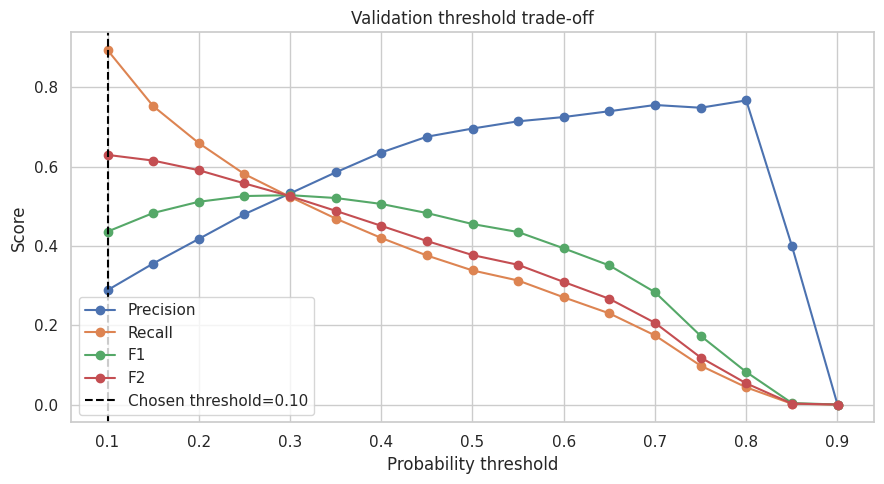

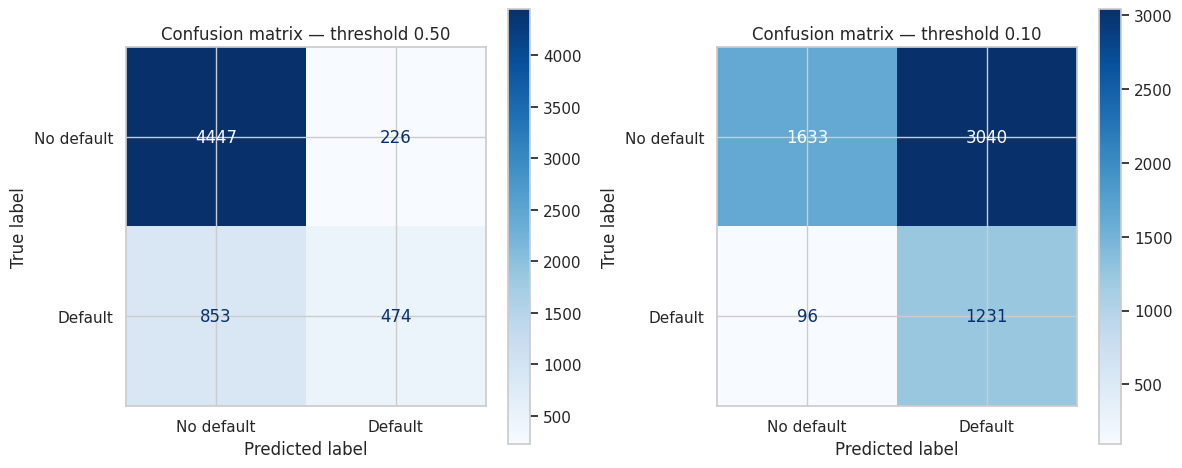

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(threshold_table["threshold"], threshold_table["precision"], marker="o", label="Precision")
plt.plot(threshold_table["threshold"], threshold_table["recall"], marker="o", label="Recall")
plt.plot(threshold_table["threshold"], threshold_table["f1"], marker="o", label="F1")
plt.plot(threshold_table["threshold"], threshold_table["f2"], marker="o", label="F2")
plt.axvline(chosen_threshold, color="black", linestyle="--", label=f"Chosen threshold={chosen_threshold:.2f}")
plt.xlabel("Probability threshold")
plt.ylabel("Score")
plt.title("Validation threshold trade-off")
plt.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, final_pred_050,
    display_labels=["No default", "Default"], ax=axes[0], cmap="Blues"
)
axes[0].set_title("Confusion matrix — threshold 0.50")
ConfusionMatrixDisplay.from_predictions(
    y_test, final_pred_tuned_threshold,
    display_labels=["No default", "Default"], ax=axes[1], cmap="Blues"
)
axes[1].set_title(f"Confusion matrix — threshold {chosen_threshold:.2f}")
plt.tight_layout()
plt.show()

## 18. Probability calibration

A probability model should ideally assign probabilities that correspond to observed frequencies. We inspect a calibration curve and Brier score. Calibration is different from ranking: a model can rank customers well but produce poorly calibrated probabilities.

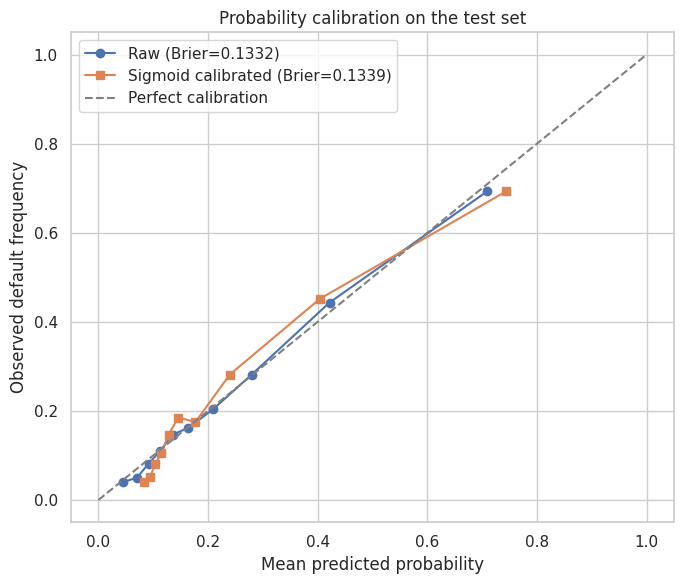

Raw Brier score: 0.1332
Calibrated Brier score: 0.1339


In [ ]:
# Fit sigmoid calibration using training data only; evaluate on the untouched test set.
calibrated_model = CalibratedClassifierCV(
    estimator=clone(tuned_model),
    method="sigmoid",
    cv=3
)
calibrated_model.fit(X_train, y_train)
calibrated_proba = calibrated_model.predict_proba(X_test)[:, 1]

prob_true_raw, prob_pred_raw = calibration_curve(y_test, final_proba, n_bins=10, strategy="quantile")
prob_true_cal, prob_pred_cal = calibration_curve(y_test, calibrated_proba, n_bins=10, strategy="quantile")

plt.figure(figsize=(7, 6))
plt.plot(prob_pred_raw, prob_true_raw, marker="o", label=f"Raw (Brier={brier_score_loss(y_test, final_proba):.4f})")
plt.plot(prob_pred_cal, prob_true_cal, marker="s", label=f"Sigmoid calibrated (Brier={brier_score_loss(y_test, calibrated_proba):.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed default frequency")
plt.title("Probability calibration on the test set")
plt.legend()
plt.tight_layout()
plt.show()

print("Raw Brier score:", round(brier_score_loss(y_test, final_proba), 4))
print("Calibrated Brier score:", round(brier_score_loss(y_test, calibrated_proba), 4))

## 19. Explainable AI

### 19.1 Permutation importance

Permutation importance measures how much a metric degrades when one feature is shuffled. It works with the full fitted pipeline and does not require model-specific internals. We use average precision as the scoring metric.

,feature,importance_mean,importance_std
5,PAY_0,0.126,0.003
29,MAX_DELAY_STATUS,0.030,0.007
28,DELAY_COUNT_6M,0.013,0.002
31,CREDIT_UTILIZATION,0.010,0.001
30,AVG_REPAYMENT_STATUS,0.009,0.002
11,BILL_AMT1,0.008,0.003
27,PAYMENT_TO_BILL_RATIO,0.007,0.004
2,EDUCATION,0.004,0.001
17,PAY_AMT1,0.002,0.001
18,PAY_AMT2,0.002,0.003


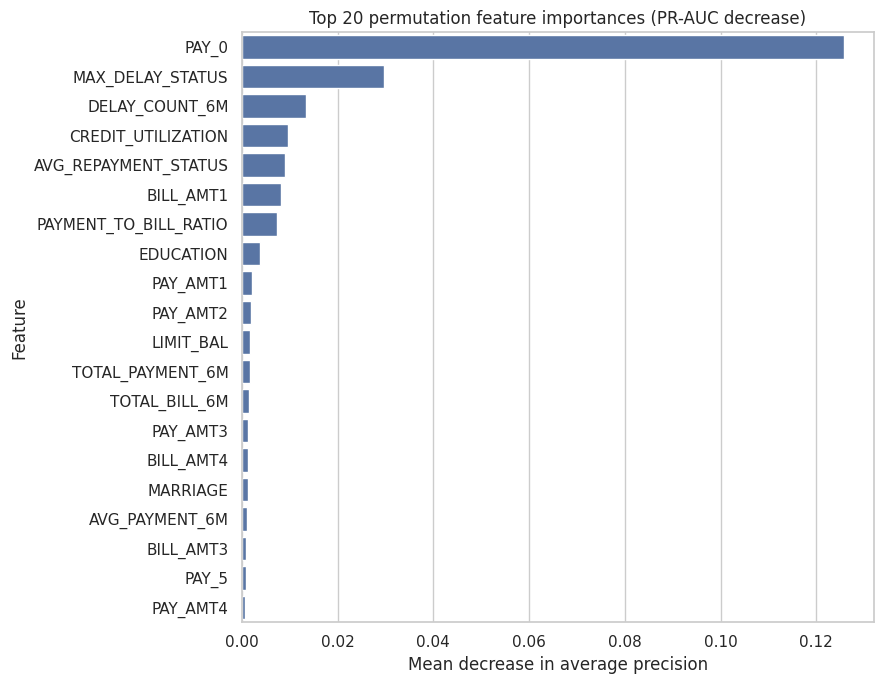

In [ ]:
perm = permutation_importance(
    tuned_model, X_test, y_test,
    n_repeats=5, random_state=RANDOM_STATE,
    scoring="average_precision", n_jobs=-1
)
perm_importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(perm_importance.head(20))
plt.figure(figsize=(9, 7))
sns.barplot(data=perm_importance.head(20), x="importance_mean", y="feature")
plt.title("Top 20 permutation feature importances (PR-AUC decrease)")
plt.xlabel("Mean decrease in average precision")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### 19.2 SHAP explanations (optional)

SHAP may require installation (`%pip install shap`). For tree-based winners, SHAP is run on a sample of transformed test rows using the fitted tree model. If the selected model is not compatible with TreeExplainer, or SHAP is unavailable, permutation importance above remains the supported model-agnostic explanation.

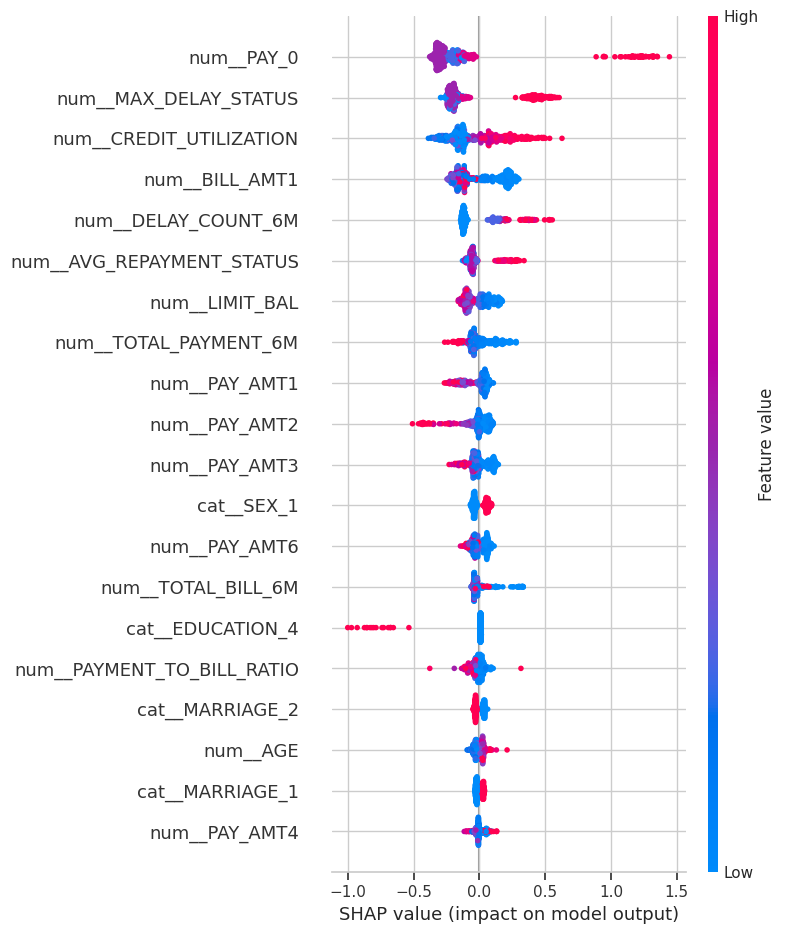

SHAP summary generated.


In [ ]:
try:
    import shap

    fitted_preprocessor = tuned_model.named_steps["preprocessor"]
    fitted_rf = tuned_model.named_steps["model"]
    X_test_transformed = fitted_preprocessor.transform(X_test.sample(min(500, len(X_test)), random_state=RANDOM_STATE))
    feature_names = fitted_preprocessor.get_feature_names_out()

    explainer = shap.TreeExplainer(fitted_rf)
    shap_values = explainer.shap_values(X_test_transformed)

    # SHAP output shape differs by SHAP/model version; select the positive class where needed.
    if isinstance(shap_values, list):
        positive_shap = shap_values[1]
    elif getattr(shap_values, "ndim", 0) == 3:
        positive_shap = shap_values[:, :, 1]
    else:
        positive_shap = shap_values

    shap.summary_plot(positive_shap, X_test_transformed, feature_names=feature_names, show=True)
    print("SHAP summary generated.")
except Exception as e:
    print("SHAP could not be generated in this environment.")
    print("Install/upgrade shap and rerun this section if desired.")
    print("Reason:", repr(e))

### 19.3 Individual prediction explanation

The function below explains one record using its predicted probability and the largest permutation-importance features. This is a transparent descriptive aid, not a causal explanation of the individual's behaviour.

In [ ]:
def explain_one_customer(row_index=0):
    row = X_test.iloc[[row_index]]
    probability = float(tuned_model.predict_proba(row)[:, 1][0])
    prediction = int(probability >= chosen_threshold)
    print(f"Predicted default probability: {probability:.2%}")
    print(f"Predicted class at threshold {chosen_threshold:.2f}: {prediction} ({'Default risk flag' if prediction else 'No default risk flag'})")
    print("\nSelected input values:")
    display(row.T.rename(columns={row.index[0]: "value"}))
    print("\nFeatures with highest global permutation importance (context only):")
    display(perm_importance.head(10))
    return probability, prediction

# Example: explain the first held-out test observation.
example_probability, example_prediction = explain_one_customer(0)

Predicted default probability: 4.26%
Predicted class at threshold 0.10: 0 (No default risk flag)

Selected input values:


,value
LIMIT_BAL,"70,000.000"
SEX,2.000
EDUCATION,1.000
MARRIAGE,2.000
AGE,27.000
PAY_0,0.000
PAY_2,0.000
PAY_3,0.000
PAY_4,0.000
PAY_5,0.000



Features with highest global permutation importance (context only):


,feature,importance_mean,importance_std
5,PAY_0,0.126,0.003
29,MAX_DELAY_STATUS,0.030,0.007
28,DELAY_COUNT_6M,0.013,0.002
31,CREDIT_UTILIZATION,0.010,0.001
30,AVG_REPAYMENT_STATUS,0.009,0.002
11,BILL_AMT1,0.008,0.003
27,PAYMENT_TO_BILL_RATIO,0.007,0.004
2,EDUCATION,0.004,0.001
17,PAY_AMT1,0.002,0.001
18,PAY_AMT2,0.002,0.003


## 20. Interactive prediction demo inside the notebook

This replaces a separate Streamlit application. Enter values for a borrower using a row from the held-out test set as a template, then modify values. The function returns a probability and class using the tuned model and validation-selected threshold.

For a compact and reliable demo, the widget form is optional. The plain Python function works in every Jupyter environment.

In [ ]:
def predict_credit_default(customer_data: dict):
    input_df = pd.DataFrame([customer_data])

    # Recalculate engineered features from the supplied six-month history.
    bill_cols_local = [f"BILL_AMT{i}" for i in range(1, 7)]
    payment_cols_local = [f"PAY_AMT{i}" for i in range(1, 7)]
    pay_status_local = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

    if all(c in input_df.columns for c in bill_cols_local):
        input_df["TOTAL_BILL_6M"] = input_df[bill_cols_local].sum(axis=1)
        input_df["AVG_BILL_6M"] = input_df[bill_cols_local].mean(axis=1)
    if all(c in input_df.columns for c in payment_cols_local):
        input_df["TOTAL_PAYMENT_6M"] = input_df[payment_cols_local].sum(axis=1)
        input_df["AVG_PAYMENT_6M"] = input_df[payment_cols_local].mean(axis=1)
    if all(c in input_df.columns for c in bill_cols_local + payment_cols_local):
        input_df["PAYMENT_TO_BILL_RATIO"] = (
            input_df["TOTAL_PAYMENT_6M"] /
            input_df["TOTAL_BILL_6M"].replace(0, np.nan)
        )
    if all(c in input_df.columns for c in pay_status_local):
        input_df["DELAY_COUNT_6M"] = (input_df[pay_status_local] > 0).sum(axis=1)
        input_df["MAX_DELAY_STATUS"] = input_df[pay_status_local].max(axis=1)
        input_df["AVG_REPAYMENT_STATUS"] = input_df[pay_status_local].mean(axis=1)
    if "BILL_AMT1" in input_df.columns and "LIMIT_BAL" in input_df.columns:
        input_df["CREDIT_UTILIZATION"] = (
            input_df["BILL_AMT1"] / input_df["LIMIT_BAL"].replace(0, np.nan)
        )

    input_df = input_df.reindex(columns=X.columns)
    probability = float(tuned_model.predict_proba(input_df)[:, 1][0])
    predicted_class = int(probability >= chosen_threshold)
    return {
        "default_probability": probability,
        "predicted_class": predicted_class,
        "risk_label": "Higher predicted default risk" if predicted_class == 1 else "Lower predicted default risk",
        "threshold": chosen_threshold
    }

# Demonstration using one held-out customer record (not a real credit decision).
demo_customer = X_test.iloc[0].to_dict()
predict_credit_default(demo_customer)

{'default_probability': 0.04264381527900696,
 'predicted_class': 0,
 'risk_label': 'Lower predicted default risk',
 'threshold': 0.1}

In [ ]:
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output

    sample = X_test.iloc[0].copy()
    fields = ["LIMIT_BAL", "AGE", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
              "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
              "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6",
              "SEX", "EDUCATION", "MARRIAGE"]
    controls = {}
    for field in fields:
        if field in categorical_features:
            opts = sorted(X[field].dropna().unique().tolist())
            controls[field] = widgets.Dropdown(options=opts, value=sample[field], description=field, layout=widgets.Layout(width="350px"))
        else:
            controls[field] = widgets.FloatText(value=float(sample[field]), description=field, layout=widgets.Layout(width="350px"))

    button = widgets.Button(description="Predict default risk", button_style="primary")
    output = widgets.Output()

    def on_predict(_):
        with output:
            clear_output()
            customer = sample.to_dict()
            for field, control in controls.items():
                customer[field] = control.value
            result = predict_credit_default(customer)
            print(f"Predicted probability: {result['default_probability']:.2%}")
            print(f"Class: {result['predicted_class']} — {result['risk_label']}")
            print(f"Threshold: {result['threshold']:.2f}")

    button.on_click(on_predict)
    display(widgets.VBox([widgets.HTML("<b>Borrower input demo (starts with a test-set example)</b>"),
                          widgets.GridBox(list(controls.values()), layout=widgets.Layout(grid_template_columns="repeat(2, 380px)")),
                          button, output]))
except Exception as e:
    print("ipywidgets is unavailable. Use predict_credit_default(demo_customer) above.")
    print("Reason:", repr(e))

## 21. Business interpretation

Use the results generated above to answer these questions:

1. Which repayment-history variables are most associated with default risk?
2. How does the chosen model trade precision for recall?
3. How many defaults are detected, and how many non-default customers are incorrectly flagged?
4. Does threshold selection materially change the confusion matrix?
5. Are predicted probabilities reasonably calibrated?
6. Do permutation importance and SHAP tell a consistent story?

**Do not write causal conclusions.** Feature importance indicates predictive contribution within this dataset and model, not that changing a feature would cause a customer to default or avoid default.

## 22. Limitations, fairness and responsible use

- The dataset is historical and specific to a particular market and period; performance may not transfer to current portfolios or other countries.
- Demographic variables such as sex and age can create fairness and legal concerns. Their presence in a benchmark dataset does not mean they should be used in real lending.
- Repayment patterns and account variables may reflect historical institutional policies and economic conditions.
- A classification threshold depends on business costs and customer impact; F2 is only an illustrative selection rule.
- The model is not a causal model and does not establish why an individual defaulted.
- Any real-world use would require representative validation, fairness and adverse-impact analysis, privacy controls, model governance, explainability review, monitoring, human oversight and legal approval.
- This notebook is an educational research prototype, not a credit scoring product or credit approval recommendation.

## 23. Save final outputs

Save the tuned model and evaluation tables for reproducibility. The model is saved with joblib; keep the Python package versions and preprocessing pipeline consistent when loading it later.

In [ ]:
import joblib
os.makedirs("artifacts", exist_ok=True)

model_file = (
    "artifacts/credit_default_"
    + best_cv_model_name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    + "_pipeline.joblib"
)
joblib.dump(tuned_model, model_file)

model_cv_results.to_csv("artifacts/model_cv_comparison.csv", index=False)
final_metrics.to_csv("artifacts/final_test_metrics.csv", index=False)
perm_importance.to_csv("artifacts/permutation_feature_importance.csv", index=False)

print("Saved model:", model_file)
print("Saved CV comparison, final test metrics and feature importance in ./artifacts/")

Saved model: artifacts/credit_default_xgboost_pipeline.joblib
Saved CV comparison, final test metrics and feature importance in ./artifacts/


## 24. Final conclusion template

Complete this section after running the notebook and reviewing the actual metrics.

- **Selected algorithm:** use the printed `best_cv_model_name` and tuned CV PR-AUC
- **Test ROC-AUC:** copy from `final_metrics`
- **Test PR-AUC:** copy from `final_metrics`
- **Precision / Recall at selected threshold:** copy from `final_metrics`
- **Most important predictive features:** [insert top features]
- **Main business insight:** [insert evidence-based observation]
- **Main limitation:** historical dataset and fairness/generalisation constraints

A strong project is not one that claims perfect prediction. It is one that demonstrates sound validation, leakage prevention, meaningful metrics, explainability and responsible interpretation.